In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, replace
from typing import Sequence, Tuple

from dispertorch import ConstantIndex, TaucLorentz
from metashapes.shape import Rectangle

from metarcwa import IsotropicMedium, Source, Stack, Lattice, Model, Layer
from metarcwa.model.adapters import from_dispertorch, from_metashapes
from metarcwa import Config, Solver, Factorization, Observables

device = "cuda:0"
dtype=torch.float32

In [2]:
def compute_rt(model: Model, config: Config) -> Tuple[torch.Tensor, torch.Tensor,
                                                        torch.Tensor, torch.Tensor]:
    """Solve the stack and return specular-order power R/T for both polarizations.

    Same convention as ``interface.ipynb``'s ``compute_rt``: reflectance is
    ``|r|**2``; transmittance additionally carries the Poynting-flux ratio
    ``Re(n_sub*cos(theta_t)) / Re(n_inc*cos(theta_i))`` between the incidence
    and transmission half-spaces (unaffected by whatever finite layer sits in
    between -- it depends only on the two half-spaces and the angle).

    Returns
    -------
    Rs, Rp, Ts, Tp : torch.Tensor
        Shape ``[N_wl, N_theta, N_phi]``, matching ``Source``'s sweep axes.
    """
    solver = Solver(model, config)
    solution = solver.run()
    obs = Observables(solution)

    rs, _ = obs.reflection(pol='s')
    _, rp = obs.reflection(pol='p')
    Rs = torch.abs(rs.cpu())**2
    Rp = torch.abs(rp.cpu())**2

    ts, _ = obs.transmission(pol='s')
    _, tp = obs.transmission(pol='p')

    n1 = (model.stack.incidence.eps_fn(model.source.wavelength)**0.5).cpu().reshape(-1, 1, 1)
    n2 = (model.stack.transmission.eps_fn(model.source.wavelength)**0.5).cpu().reshape(-1, 1, 1)

    theta = model.source.theta.cpu().reshape(1, -1, 1)
    cos_i = torch.cos(theta)
    sin_t = (n1 / n2) * torch.sin(theta)
    cos_t = torch.sqrt(1 - sin_t**2 + 0j)
    coeff = torch.real(n2 * cos_t) / torch.real(n1 * cos_i)

    Ts = coeff * torch.abs(ts.cpu())**2
    Tp = coeff * torch.abs(tp.cpu())**2
    return Rs, Rp, Ts, Tp

In [3]:
# Define materials
wl = torch.linspace(400, 1000, 121)

disp_inc = ConstantIndex(1.0)
disp_trans = ConstantIndex(1.46)

# LPCVD aSi dispersion (Tauc-Lorentz parameters were fitted to ridb)
A = torch.tensor(198.9501)
omega_0 = torch.tensor(3.6085)
gamma = torch.tensor(2.5392)
E_g = torch.tensor(1.4600)
disp_meta = TaucLorentz(A = A, omega_0=omega_0, gamma=gamma, E_g = E_g)

medium_inc = IsotropicMedium(from_dispertorch(disp_inc))
medium_trans = IsotropicMedium(from_dispertorch(disp_trans))
medium_meta = IsotropicMedium(from_dispertorch(disp_meta))

In [4]:
# Define Lattice
period = 600.0 # nm
lattice = Lattice.rectangular(period, period)

In [5]:
# Define shape
xc, yc = torch.tensor(period/2), torch.tensor(period/2)
width = torch.tensor(267)
height = torch.tensor(282)

shape = Rectangle(center=(xc, yc), size=(width, height))

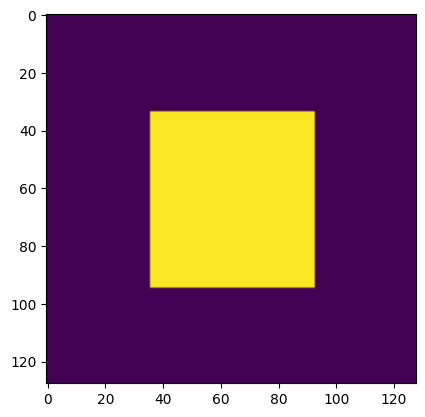

In [6]:
# Build model
d = torch.tensor(175.0)
layer = Layer(medium_meta, d, medium_inc, from_metashapes(shape))

stack = Stack(medium_inc, [layer], medium_trans, lattice)
source = Source(wl)

model = Model(stack, source)

plt.imshow(model.spec(128, 128).layers[0].pattern)

In [12]:
# Prepare config and solve
nx = 128
ny = 128

m = 10
n = 10

factorization = Factorization("Jones")
config = Config(dtype, device, nx, ny, m, n, factorization=factorization)
Rs, Rp, Ts, Tp = compute_rt(model, config)

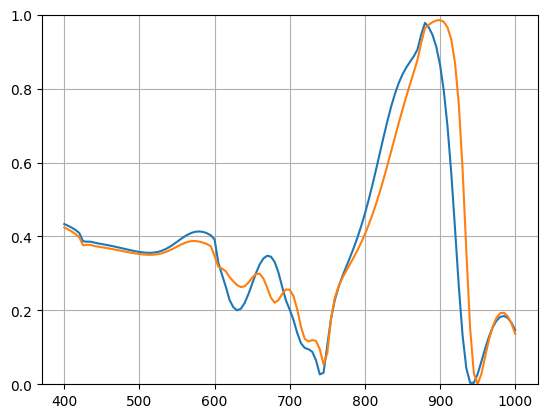

In [13]:
plt.plot(wl, Ts[:, 0, 0])
plt.plot(wl, Tp[:, 0, 0])
plt.ylim([0, 1])
#plt.xlim([450, 730])
plt.grid()